# 2 · An HMM over primitives — small prototype to judge whether it makes sense

Each minimum-jerk primitive (from `cache_primitives.py`) is one observation; a session is one sequence of primitives in time order, across movements. Hidden states = **primitive types**; the transition matrix = which type tends to follow which.

Features per primitive (z-scored once on the pooled data, never per session):
- `sizeD` = sign(D) · log10(|D| / 1 mrad): signed size, rightward > 0, leftward < 0
- `logT` = log10 duration (s)
- `log_ioi` = log10 time since the previous primitive started (s): short inside a movement, long between movements

Direction is in the emissions, so states come in left/right versions and reversals live in the transition matrix. (A first version used a binary same/reversed feature: the HMM split on it alone and states mostly separated mice.)

Data, kept small on purpose: **CSHL049 and UCLA017** (the two mice the first version split apart), **first, middle and last training session** each. Gaussian HMM, full covariance, `hmmlearn`.

*Archived (2026-11-05): an approach that was not taken forward. Kept for reference; outputs are from the original run.*

In [1]:
import sys; sys.path.insert(0, '..')   # archived: the modules live one folder up
import os
os.environ['OMP_NUM_THREADS'] = os.environ['OPENBLAS_NUM_THREADS'] = os.environ['MKL_NUM_THREADS'] = '1'   # tiny matrices: threads only slow it down
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from hmmlearn.hmm import GaussianHMM
import wheel_states as ws, primitives as pr

PDIR = ws.DM_DIR.parent / 'wheel_primitives'
FEATS = ['sizeD', 'logT', 'log_ioi']
MICE = ['CSHL049', 'UCLA017']
man = ws.manifest()

seqs = []
for mouse in MICE:
    m = man.query('mouse == @mouse').sort_values('session_index')
    for _, r in m.iloc[[0, len(m) // 2, -1]].iterrows():
        p = pd.read_parquet(PDIR / f'primitives_{r.eid}_{mouse}').sort_values('start')
        p = p[p.D.abs() > 1e-3].reset_index(drop=True)
        p['sizeD'] = np.sign(p.D) * np.log10(p.D.abs() / 1e-3)
        p['logT'] = np.log10(p.duration)
        p['log_ioi'] = np.log10(np.r_[10, np.maximum(np.diff(p.start.values), .01)])
        p['mouse'], p['eid'], p['session_index'] = mouse, r.eid, r.session_index
        p['seq'] = len(seqs)
        seqs.append(p)
P = pd.concat(seqs, ignore_index=True)
MU, SD = P[FEATS].mean(), P[FEATS].std()
Z = lambda p: ((p[FEATS] - MU) / SD).values
print(P.groupby(['mouse', 'session_index']).size().rename('primitives'))

mouse    session_index
CSHL049  1                2523
         8                5609
         15               5167
UCLA017  1                 996
         18               2041
         35               3139
Name: primitives, dtype: int64


## Feature space

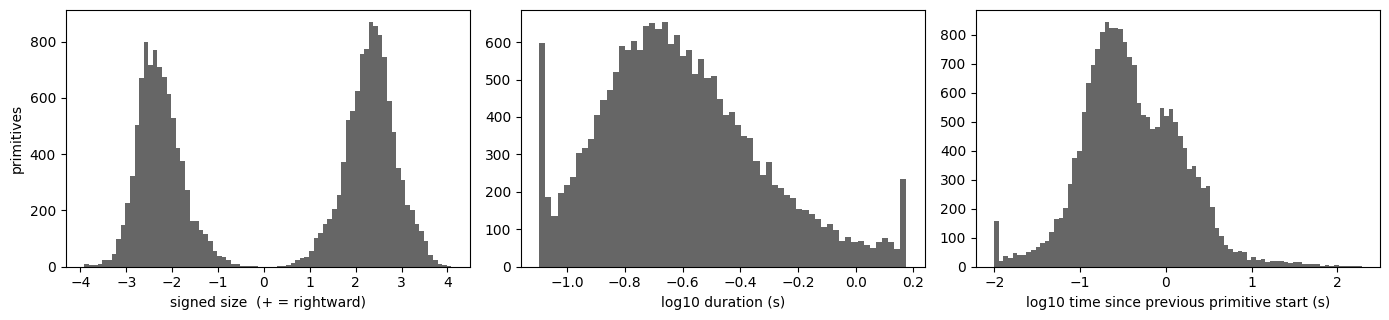

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.3))
axs[0].hist(P.sizeD, 80, color='0.4'); axs[0].set(xlabel='signed size  (+ = rightward)', ylabel='primitives')
axs[1].hist(P.logT, 60, color='0.4'); axs[1].set(xlabel='log10 duration (s)')
axs[2].hist(P.log_ioi, 80, color='0.4'); axs[2].set(xlabel='log10 time since previous primitive start (s)')
plt.tight_layout()

In [3]:
def fit(K, X, L, seed):
    try:
        m = GaussianHMM(K, covariance_type='full', n_iter=100, tol=1e-3, random_state=seed, min_covar=1e-2).fit(X, L)
        return m, m.score(X, L)
    except ValueError:      # a degenerate covariance in this initialisation
        return None, -np.inf

def best_fit(K, idx, seeds=(0, 1, 2)):
    X, L = np.concatenate([Z(seqs[i]) for i in idx]), [len(seqs[i]) for i in idx]
    fits = Parallel(n_jobs=len(seeds))(delayed(fit)(K, X, L, s) for s in seeds)
    return max(fits, key=lambda f: f[1])[0]

K = 8     # fixed for now; a held-out sweep on these 6 sessions was too noisy to choose K

## Fit on all six sessions

In [4]:
import time
t = time.time()
hmm = best_fit(K, range(len(seqs)), seeds=(0, 1, 2, 3, 4))
print(f'fit: {time.time() - t:.1f} s, converged: {hmm.monitor_.converged}')
for p in seqs:
    p['state'] = hmm.predict(Z(p))
P = pd.concat(seqs, ignore_index=True)
order = P.groupby('state').sizeD.mean().sort_values().index        # 0 = biggest leftward ... K-1 = biggest rightward
relabel = {s: i for i, s in enumerate(order)}
for p in seqs: p['state'] = p.state.map(relabel)
P['state'] = P.state.map(relabel)
A = hmm.transmat_[np.ix_(order, order)]
COL = plt.cm.coolwarm(np.linspace(0, 1, K))       # blue = leftward, red = rightward

desc = P.groupby('state').agg(fraction=('D', lambda x: len(x) / len(P)),
                              median_D_rad=('D', 'median'),
                              median_T_ms=('duration', lambda x: 1000 * x.median()),
                              median_ioi_s=('log_ioi', lambda x: 10 ** x.median()))
desc['p_stay'] = np.diag(A)
for e in pr.EPOCHS:
    desc[f'frac_{e}'] = P.groupby('state').epoch.apply(lambda x: (x == e).mean())
desc.round(3)

fit: 4.2 s, converged: True


,fraction,median_D_rad,median_T_ms,median_ioi_s,p_stay,frac_pre-stim,frac_response,frac_post-feedback
state,,,,,,,,
0,0.194,-0.335,212.276,0.397,0.297,0.289,0.414,0.297
1,0.151,-0.193,302.397,0.468,0.358,0.226,0.492,0.282
2,0.044,-0.075,243.722,0.861,0.215,0.237,0.546,0.217
3,0.063,-0.056,124.794,0.159,0.168,0.205,0.550,0.245
4,0.099,0.061,125.270,0.252,0.289,0.187,0.508,0.305
5,0.041,0.085,306.335,0.776,0.110,0.144,0.421,0.436
6,0.151,0.225,288.879,0.365,0.362,0.214,0.459,0.328
7,0.257,0.389,259.848,0.330,0.431,0.244,0.429,0.327


### What each state emits

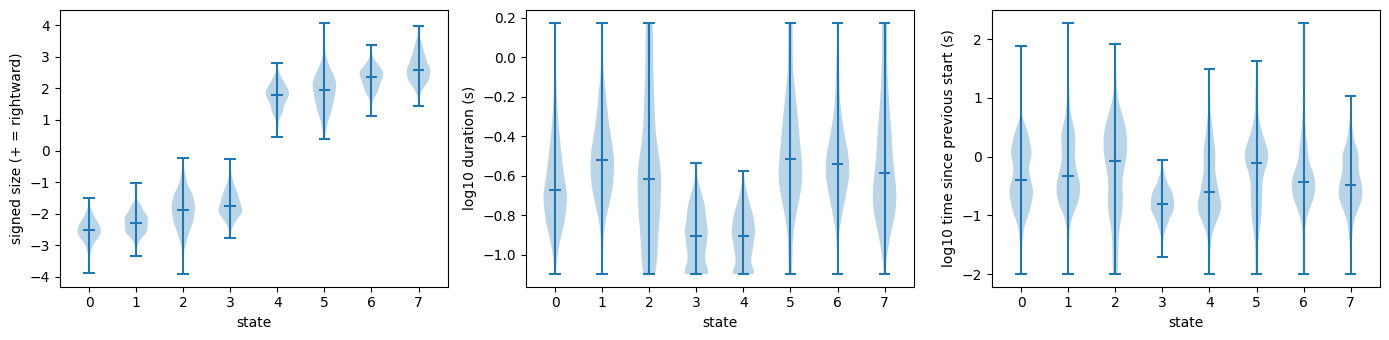

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
for f, ax, lab in zip(FEATS, axs, ['signed size (+ = rightward)', 'log10 duration (s)', 'log10 time since previous start (s)']):
    ax.violinplot([P.loc[P.state == s, f] for s in range(K)], positions=range(K), showmedians=True)
    ax.set(xlabel='state', ylabel=lab, xticks=range(K))
plt.tight_layout()

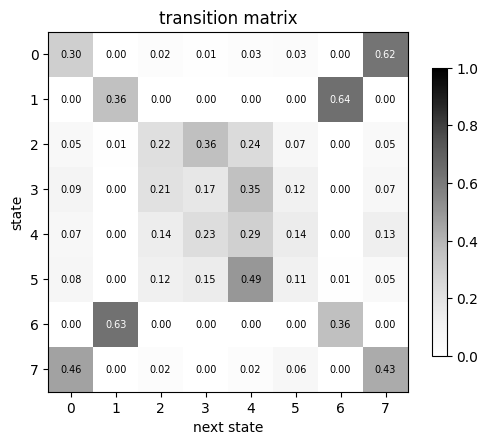

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(A, cmap='Greys', vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f'{A[i, j]:.2f}', ha='center', va='center', fontsize=7, color='w' if A[i, j] > .5 else 'k')
ax.set(xlabel='next state', ylabel='state', title='transition matrix', xticks=range(K), yticks=range(K))
plt.colorbar(im, shrink=.8); plt.tight_layout()

### Gallery: random examples of each state in context (thick colour = that primitive, grey = measured velocity, thin = other primitives)

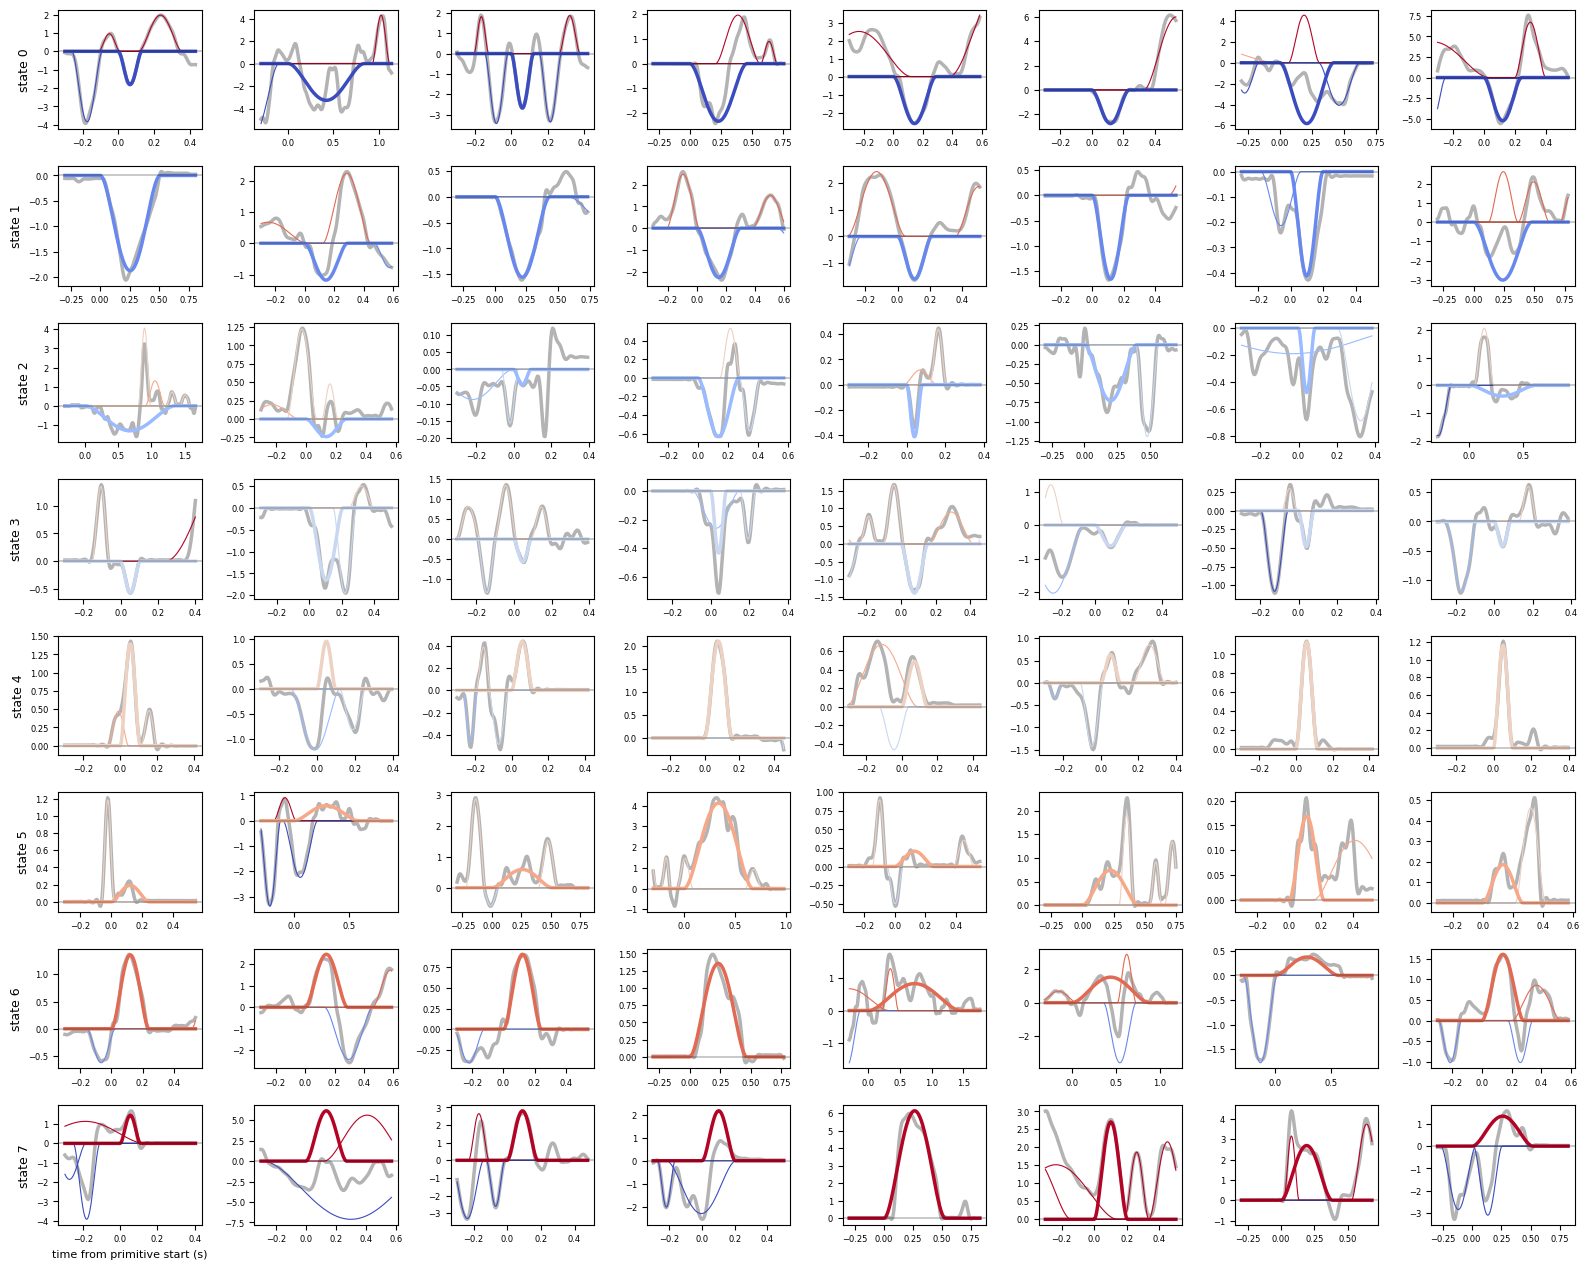

In [7]:
DM = {p.eid[0]: ws.load_session(p.eid[0], p.mouse[0])[0] for p in seqs}
rng = np.random.default_rng(0)
N_EX = 8
fig, axs = plt.subplots(K, N_EX, figsize=(2 * N_EX, 1.6 * K), squeeze=False)
for s in range(K):
    for c, i in enumerate(rng.choice(P.index[P.state == s], N_EX, replace=False)):
        r = P.loc[i]; dm = DM[r.eid]; ax = axs[s, c]
        t0, t1 = r.start - .3, r.start + r.duration + .3
        sel = (dm.times > t0) & (dm.times < t1)
        ax.plot(dm.times[sel] - r.start, dm.velocity[sel], c='0.7', lw=2.5)
        q = P[(P.eid == r.eid) & (P.start < t1) & (P.start + P.duration > t0)]
        tt = dm.times[sel].values
        for _, o in q.iterrows():
            ax.plot(tt - r.start, pr.minjerk(tt, o.start, o.duration, o.D), c=COL[o.state], lw=.8)
        ax.plot(tt - r.start, pr.minjerk(tt, r.start, r.duration, r.D), c=COL[s], lw=2.5)
        ax.axhline(0, c='k', lw=.3); ax.tick_params(labelsize=6)
        if c == 0: ax.set_ylabel(f'state {s}', fontsize=9)
axs[-1, 0].set_xlabel('time from primitive start (s)', fontsize=8)
plt.tight_layout()

### Velocity traces with every primitive shaded by its state

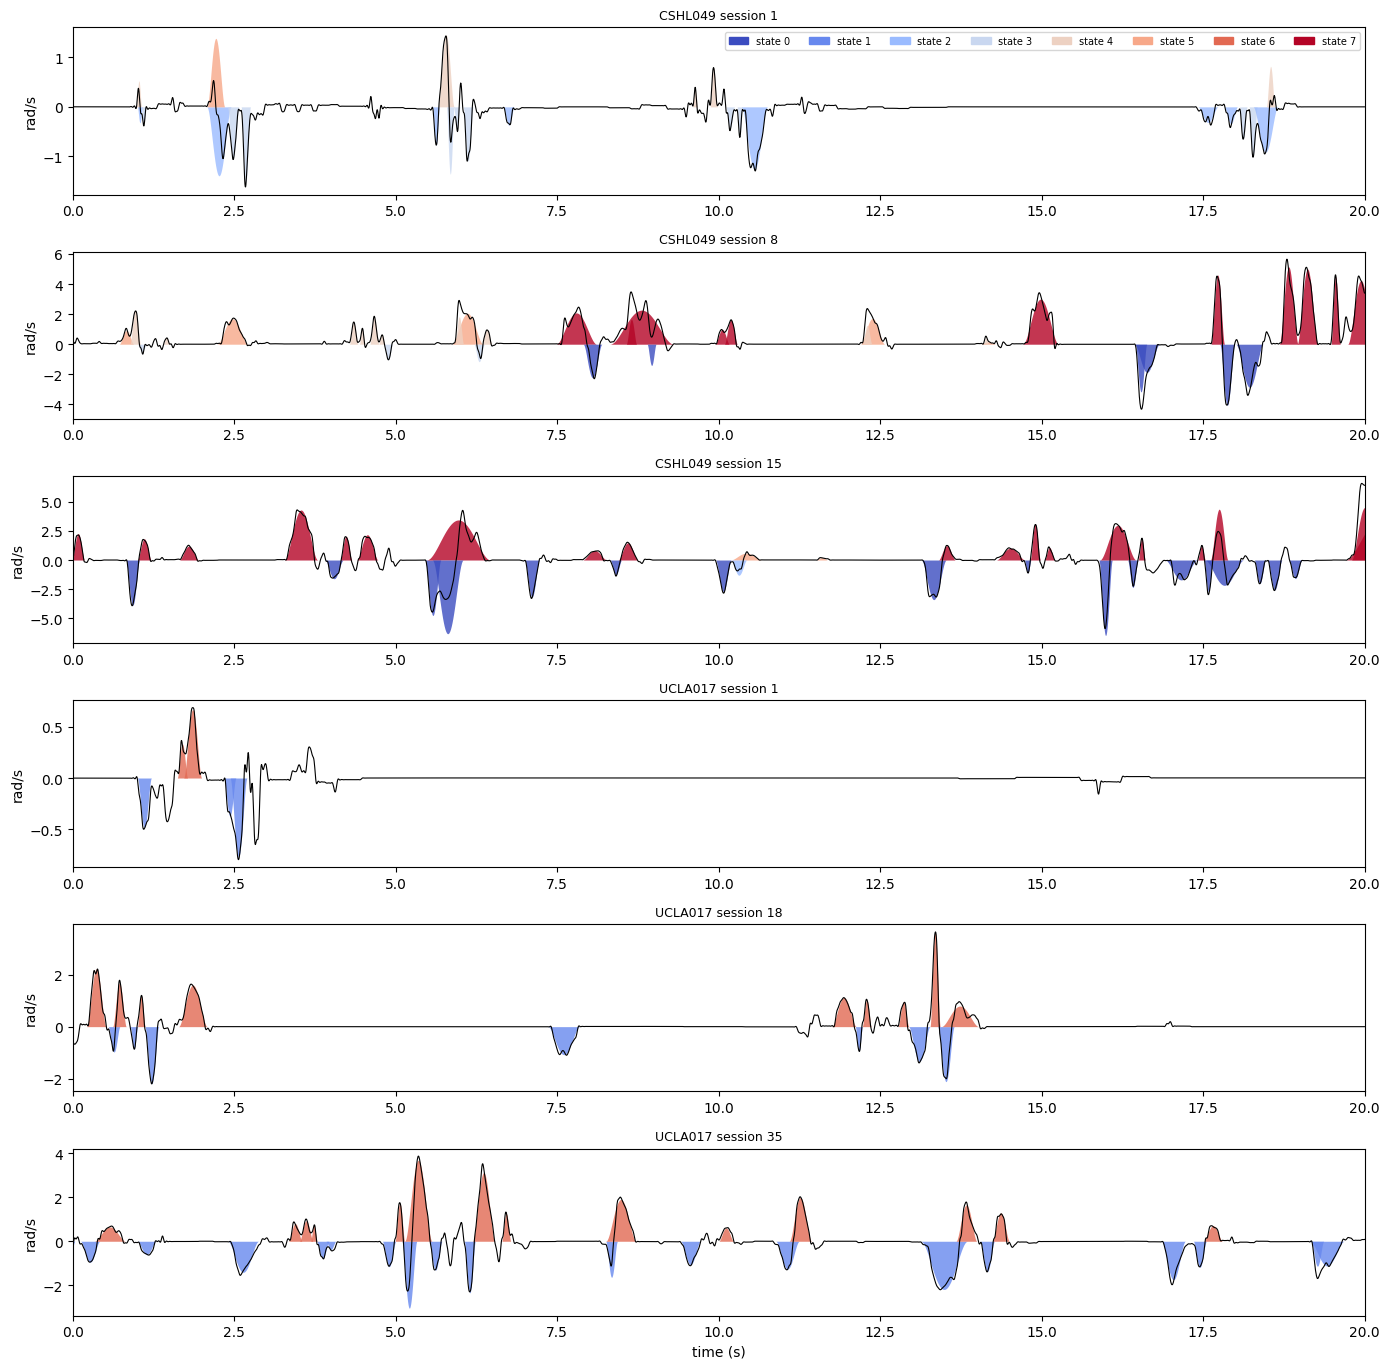

In [8]:
fig, axs = plt.subplots(len(seqs), 1, figsize=(14, 2.3 * len(seqs)))
for ax, p in zip(axs, seqs):
    dm = DM[p.eid[0]]
    t0 = p.start.iloc[len(p) // 2] - 1      # start just before a primitive, so the window isn't all stillness
    sel = (dm.times > t0) & (dm.times < t0 + 20)
    ax.plot(dm.times[sel] - t0, dm.velocity[sel], c='k', lw=.8)
    for _, r in p[(p.start > t0 - 1) & (p.start < t0 + 20)].iterrows():
        tt = np.linspace(r.start, r.start + r.duration, 40)
        ax.fill_between(tt - t0, pr.minjerk(tt, r.start, r.duration, r.D), color=COL[r.state], alpha=.8, lw=0)
    ax.set(xlim=(0, 20), ylabel='rad/s', title=f'{p.mouse[0]} session {p.session_index[0]}')
    ax.title.set_fontsize(9)
axs[-1].set_xlabel('time (s)')
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[s]) for s in range(K)]
axs[0].legend(handles, [f'state {s}' for s in range(K)], fontsize=7, ncol=K, loc='upper right')
plt.tight_layout()

### Most common state sequences within a movement

In [9]:
words = P.groupby(['seq', 'movement']).state.apply(lambda x: '-'.join(map(str, x)))
top = words.value_counts().head(20)
print(f'{len(words)} movements, {words.nunique()} distinct sequences; top 20 cover {top.sum() / len(words):.0%}')
top.to_frame('movements')

7008 movements, 938 distinct sequences; top 20 cover 58%


,movements
state,
1,526
6,451
7,436
0-7,412
1-6,307
1-1,181
4,181
7-7,174
6-6,160


## Are the states shared by both mice? How does usage change over training?

state                      0      1      2      3      4      5      6      7
mouse   session_index                                                        
CSHL049 1              0.118  0.009  0.191  0.254  0.239  0.074  0.005  0.110
        8              0.221  0.000  0.038  0.068  0.181  0.069  0.000  0.423
        15             0.405  0.008  0.027  0.036  0.056  0.041  0.008  0.419
UCLA017 1              0.021  0.479  0.013  0.006  0.006  0.007  0.418  0.050
        18             0.063  0.390  0.006  0.003  0.004  0.002  0.462  0.068
        35             0.001  0.513  0.000  0.000  0.000  0.001  0.484  0.001

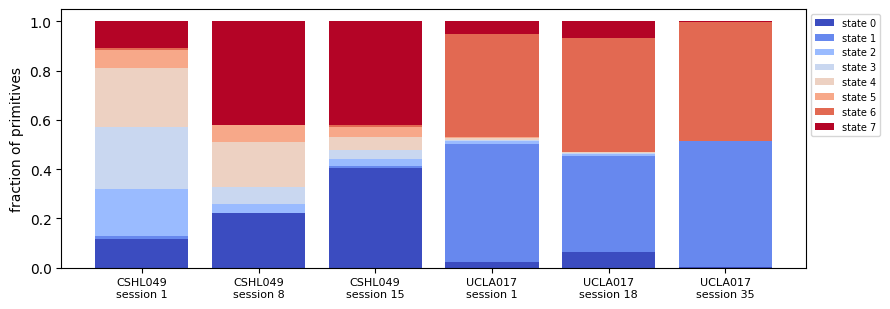

In [10]:
u = P.groupby(['mouse', 'session_index']).state.value_counts(normalize=True).unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.2))
bottom = np.zeros(len(u))
for s in range(K):
    ax.bar(range(len(u)), u[s], bottom=bottom, color=COL[s], label=f'state {s}'); bottom += u[s].values
ax.set_xticks(range(len(u)), [f'{m}\nsession {k}' for m, k in u.index], fontsize=8)
ax.set(ylabel='fraction of primitives'); ax.legend(fontsize=7, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout(); u.round(3)